In [1]:
%% MIT 18.03 Lecture 3: First-Order LTI Systems (Pure Base MATLAB Version)
% Description: Simulates first-order dynamic systems (RC Circuit) without
%              relying on Control System Toolbox. Uses pure ODE integration
%              and complex arithmetic to compute time and frequency responses.
%
% % MBD Concept Mapping: Maps plant dynamics directly via state differential
%                      equations and complex frequency response G(j*omega),
%                      demonstrating that transfer functions originate from ODEs.


clear; clc; close all;


%% 1. Physical System Parameter Definitions (Series RC Circuit)
R = 1000;          % Resistance: 1000 Ohms
C = 1e-6;          % Capacitance: 1 uF (1e-6 Farads)
tau = R * C;       % System Time Constant: tau = RC (0.001 s)
omega_c = 1 / tau; % Cutoff frequency: omega_c = 1/tau (1000 rad/s)


fprintf('=== First-Order LTI System Characteristics ===\n');

=== First-Order LTI System Characteristics ===

In [2]:
fprintf('Resistance (R)      : %.2f Ohm\n', R);

Resistance (R)      : 1000.00 Ohm

In [3]:
fprintf('Capacitance (C)     : %.2e F\n', C);

Capacitance (C)     : 1.00e-06 F

In [4]:
fprintf('Time Constant (tau) : %.4e s\n', tau);

Time Constant (tau) : 1.0000e-03 s

In [5]:
fprintf('System Pole (p)     : %.4f rad/s\n', -1/tau);

System Pole (p)     : -1000.0000 rad/s

In [6]:
fprintf('Cutoff Frequency    : %.2f rad/s (%.2f Hz)\n', omega_c, omega_c / (2*pi));

Cutoff Frequency    : 1000.00 rad/s (159.15 Hz)

In [7]:
fprintf('==============================================\n\n');


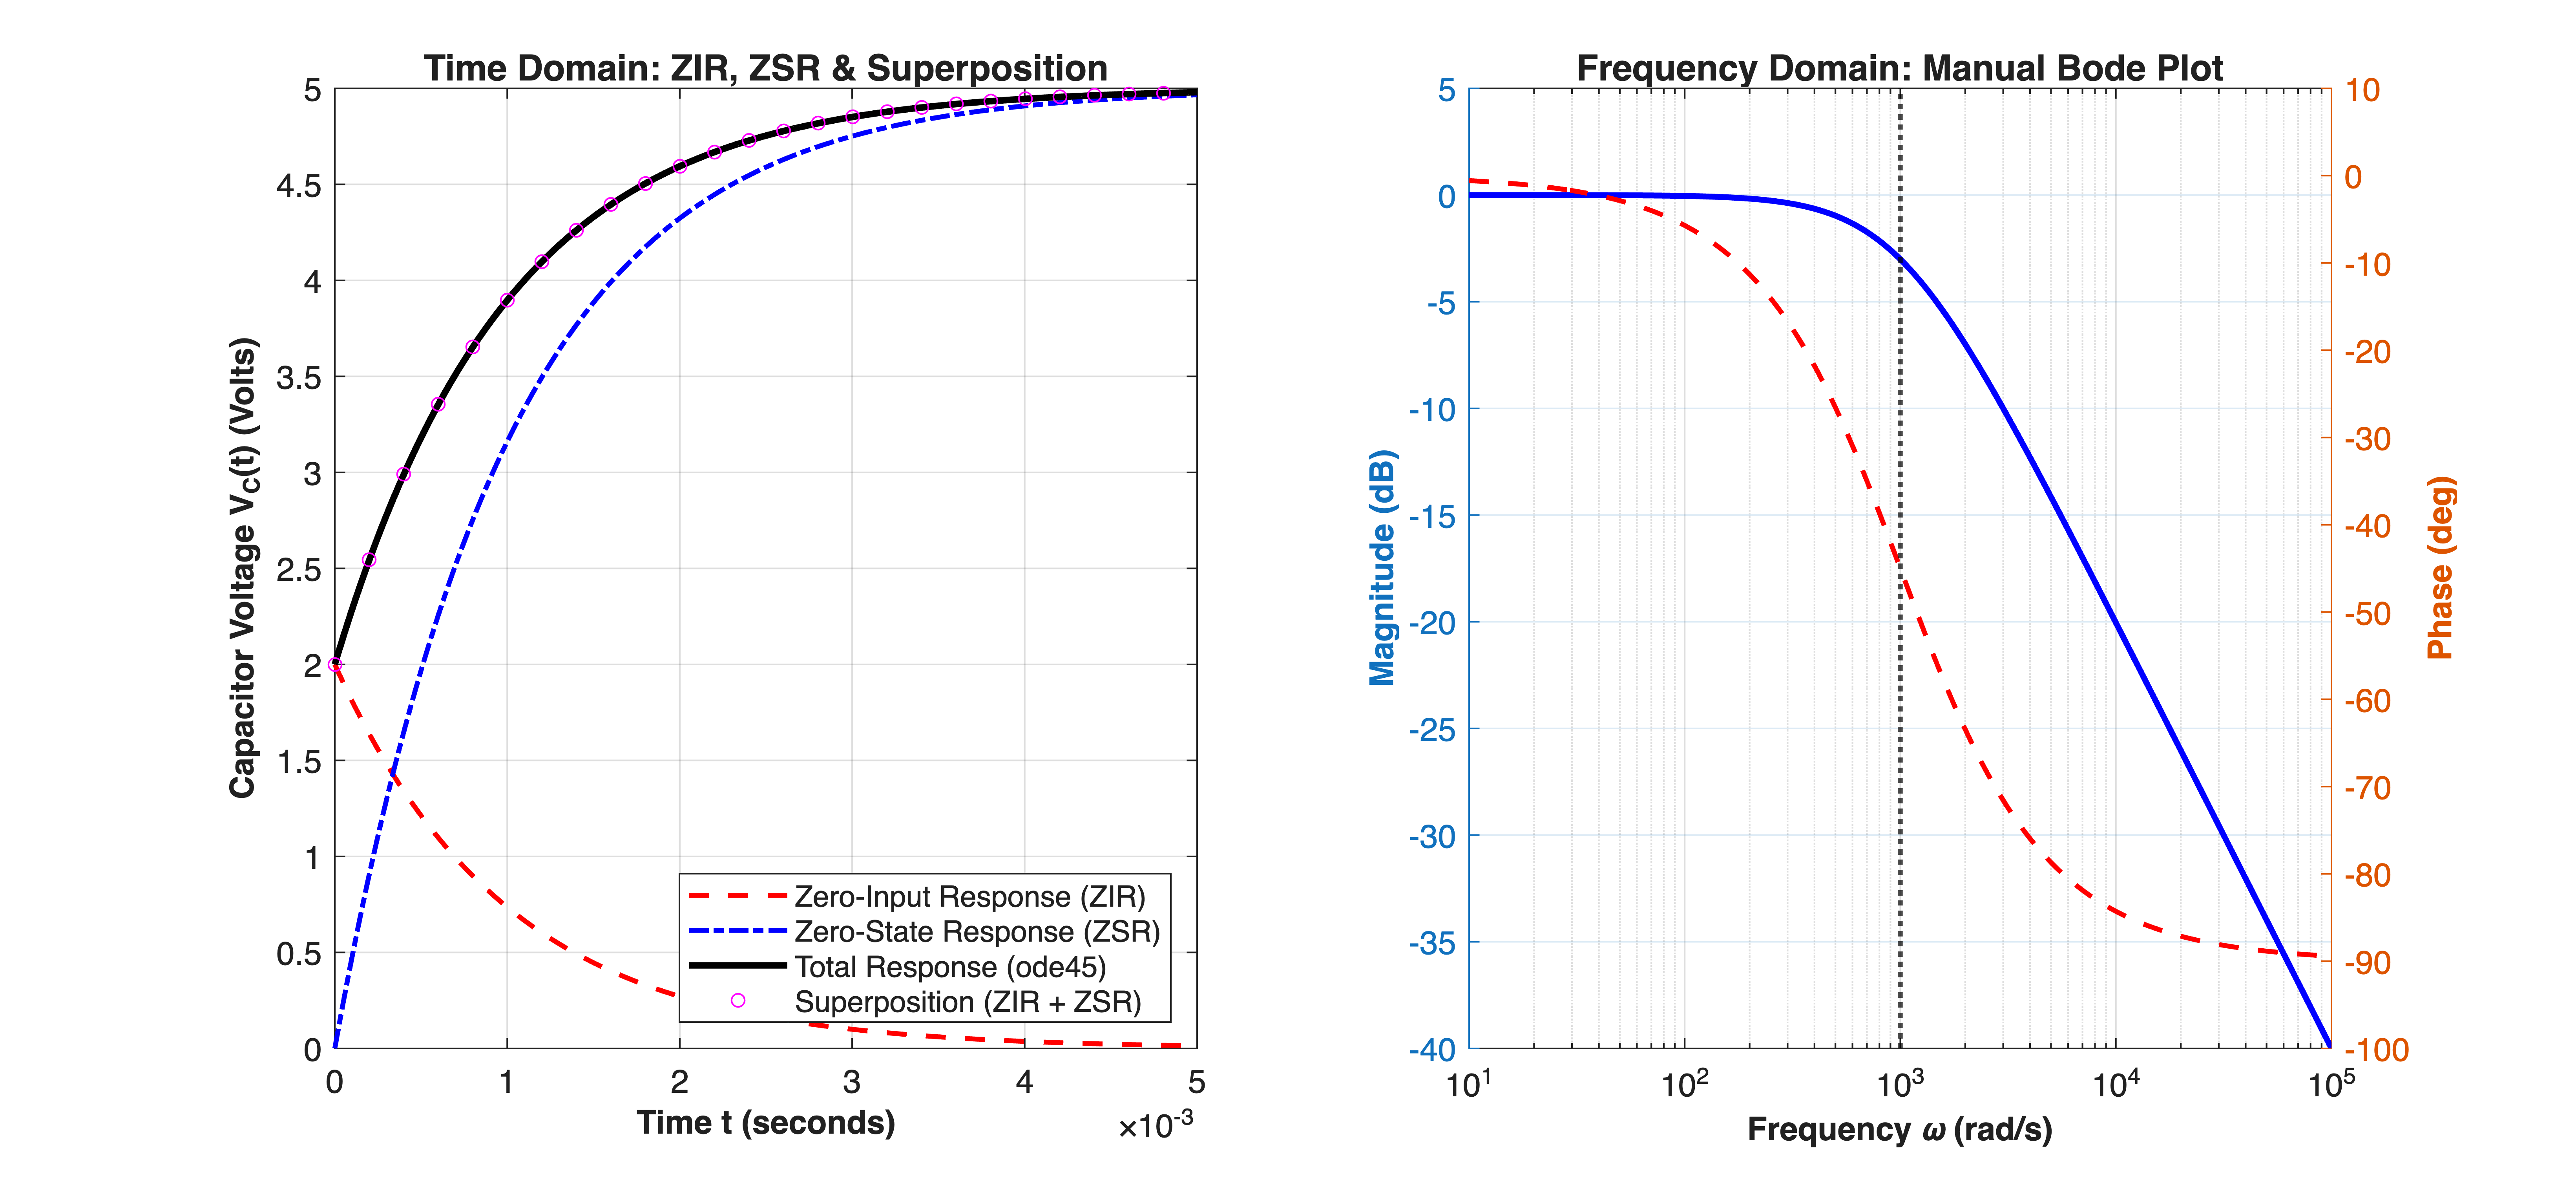

In [8]:


%% 2. Time-Domain Response Decomposition: ZIR + ZSR = Total Response
t_span = [0, 5 * tau];
t_eval = linspace(t_span(1), t_span(2), 1000);
y0 = 2.0;          % Initial state condition: V_c(0) = 2.0 V
u_val = 5.0;       % Constant step input voltage: 5.0 V


% ODE Definitions: dy/dt = (u(t) - y) / tau
ode_total = @(t, y) (u_val - y) / tau;
ode_zir   = @(t, y) (-y) / tau;
ode_zsr   = @(t, y) (u_val - y) / tau;


opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);


% Solve Zero-Input Response (ZIR): initial state y0, input = 0
[~, y_zir] = ode45(ode_zir, t_eval, y0, opts);


% Solve Zero-State Response (ZSR): initial state = 0, input active
[~, y_zsr] = ode45(ode_zsr, t_eval, 0, opts);


% Solve Total Response: initial state y0, input active
[~, y_total] = ode45(ode_total, t_eval, y0, opts);


%% 3. Frequency-Domain Calculation via Complex Arithmetic (Manual Bode)
% Transfer Function: G(s) = 1 / (tau*s + 1), evaluated at s = j*omega
w = logspace(log10(omega_c * 0.01), log10(omega_c * 100), 500); % Frequency vector
s = 1i * w;
G = 1 ./ (tau * s + 1);


mag_dB = 20 * log10(abs(G));
phase_deg = angle(G) * (180 / pi);


%% 4. Figure Generation: Time-Domain & Frequency-Domain Subplots
figure('Color', [1 1 1], 'Position', [100, 100, 1050, 480]);


% Subplot 1: Time Domain Superposition Verification
subplot(1, 2, 1);
plot(t_eval, y_zir, 'r--', 'LineWidth', 1.5, 'DisplayName', 'Zero-Input Response (ZIR)');
hold on; grid on; box on;
plot(t_eval, y_zsr, 'b-.', 'LineWidth', 1.5, 'DisplayName', 'Zero-State Response (ZSR)');
plot(t_eval, y_total, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Total Response (ode45)');
plot(t_eval, y_zir + y_zsr, 'mo', 'MarkerIndices', 1:40:length(t_eval), ...
    'MarkerSize', 4, 'DisplayName', 'Superposition (ZIR + ZSR)');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Capacitor Voltage V_C(t) (Volts)', 'FontSize', 10, 'FontWeight', 'bold');
title('Time Domain: ZIR, ZSR & Superposition', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'southeast', 'FontSize', 9);
xlim([0, 5 * tau]);


% Subplot 2: Frequency Domain Bode Diagram (Magnitude & Phase)
subplot(1, 2, 2);
yyaxis left;
semilogx(w, mag_dB, 'b-', 'LineWidth', 1.8);
ylabel('Magnitude (dB)', 'FontSize', 10, 'FontWeight', 'bold');
ylim([-40, 5]);


yyaxis right;
semilogx(w, phase_deg, 'r--', 'LineWidth', 1.5);
ylabel('Phase (deg)', 'FontSize', 10, 'FontWeight', 'bold');
ylim([-100, 10]);


grid on; box on;
xlabel('Frequency \omega (rad/s)', 'FontSize', 10, 'FontWeight', 'bold');
title('Frequency Domain: Manual Bode Plot', 'FontSize', 11, 'FontWeight', 'bold');
xline(omega_c, 'k:', 'LineWidth', 1.5);

In [9]:


fprintf('Script executed successfully using Base MATLAB.\n');

Script executed successfully using Base MATLAB.